Working directory: c:\Users\gamer\Documents\projects\cms-medicare-audit-analysis


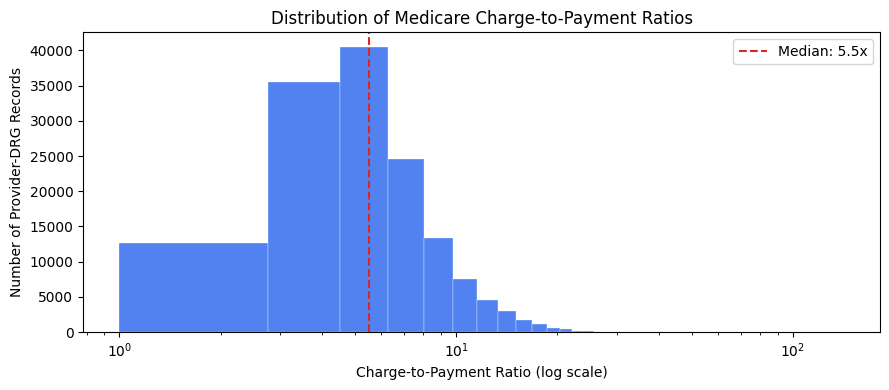

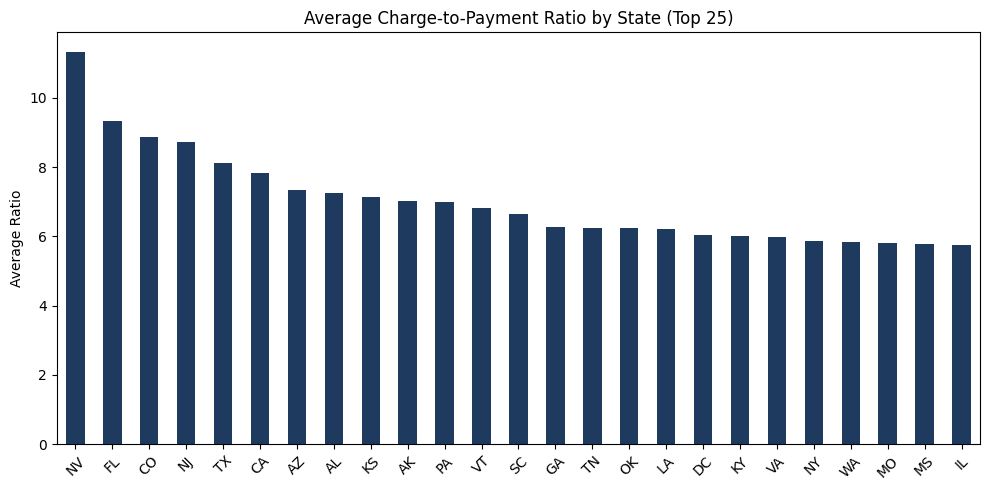

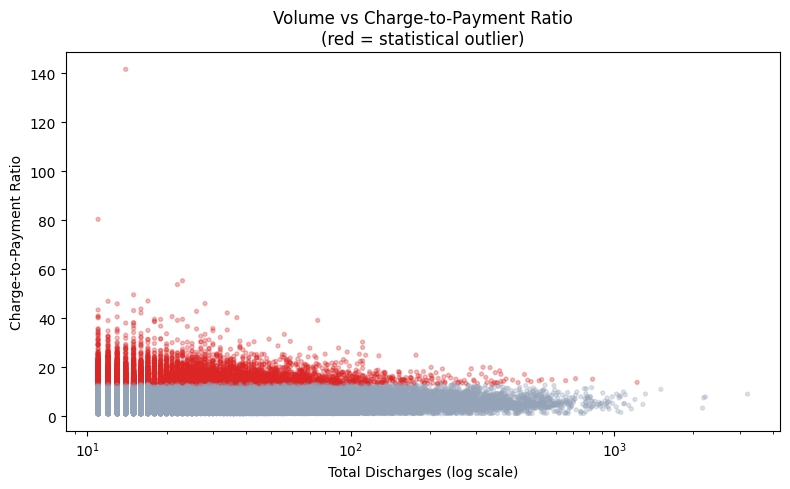

In [1]:
# 02_eda.ipynb — Key charts
import matplotlib.pyplot as plt
import pandas as pd

# Run once — sets working directory to project root regardless of where notebook is
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print('Working directory:', os.getcwd())

df = pd.read_csv('data/processed/cms_clean.csv')

# ── Chart 1: Ratio distribution (log scale) ──────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df['charge_to_payment_ratio'], bins=80, color='#2563EB', alpha=0.8,
        edgecolor='white', linewidth=0.3)
ax.axvline(df['charge_to_payment_ratio'].median(), color='#DC2626',
           linestyle='--', label=f'Median: {df['charge_to_payment_ratio'].median():.1f}x')
ax.set_xscale('log')
ax.set_xlabel('Charge-to-Payment Ratio (log scale)')
ax.set_ylabel('Number of Provider-DRG Records')
ax.set_title('Distribution of Medicare Charge-to-Payment Ratios')
ax.legend()
plt.tight_layout()
plt.savefig('outputs/figures/ratio_distribution.png', dpi=150, bbox_inches='tight')

# ── Chart 2: Average ratio by state (top 25) ─────────────────
state_ratio = (df.groupby('Rndrng_Prvdr_State_Abrvtn')['charge_to_payment_ratio']
               .mean().sort_values(ascending=False).head(25))

fig, ax = plt.subplots(figsize=(10, 5))
state_ratio.plot(kind='bar', color='#1E3A5F', ax=ax)
ax.set_title('Average Charge-to-Payment Ratio by State (Top 25)')
ax.set_ylabel('Average Ratio')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('outputs/figures/ratio_by_state.png', dpi=150, bbox_inches='tight')

# ── Chart 3: Volume vs ratio scatter ─────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
colors = df['ratio_outlier_flag'].map({True:'#DC2626', False:'#94A3B8'})
ax.scatter(df['Tot_Dschrgs'], df['charge_to_payment_ratio'],
           c=colors, alpha=0.3, s=8)
ax.set_xscale('log')
ax.set_xlabel('Total Discharges (log scale)')
ax.set_ylabel('Charge-to-Payment Ratio')
ax.set_title('Volume vs Charge-to-Payment Ratio\n(red = statistical outlier)')
plt.tight_layout()
plt.savefig('outputs/figures/volume_vs_ratio.png', dpi=150, bbox_inches='tight')